Hands-On Data Lab Implementation

Name: Arifa Begum R

1. Environment Setup
Tools used: Python, Jupyter Notebook, NumPy, Pandas, Matplotlib.

In [2]:
!mamba install pandas matplotlib

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 5.042 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.0.6    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


In [3]:
# Code
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.13.1
NumPy: 2.5.3
Pandas: 3.0.6
Matplotlib: 3.11.1


Libraries used
- NumPy:fast calculations on numbers and arrays.
- Pandas:working with data in table form (DataFrames).
- Matplotlib:drawing charts.

2. Dataset
A small dataset of 12 students with department, attendance, study hours and marks.

In [4]:
# code
data = {
    "student": ["Anu", "Bala", "Chitra", "Deepa", "Esha", "Farah",
                "Gita", "Hari", "Indu", "Jaya", "Kavi", "Lata"],
    "department": ["DS", "CS", "DS", "IT", "DS", "CS",
                   "IT", "DS", "CS", "IT", "DS", "CS"],
    "attendance": [92, 78, 88, 65, 95, 82, 70, 90, 85, 60, 97, 75],
    "study_hours": [3.5, 2.0, 3.0, 1.5, 4.0, 2.5, 2.0, 3.5, 3.0, 1.0, 4.5, 2.0],
    "marks": [88, 70, 82, 58, 94, 74, 63, 85, 79, 52, 96, 68]
}

df = pd.DataFrame(data)
df

,student,department,attendance,study_hours,marks
0,Anu,DS,92,3.5,88
1,Bala,CS,78,2.0,70
2,Chitra,DS,88,3.0,82
3,Deepa,IT,65,1.5,58
4,Esha,DS,95,4.0,94
5,Farah,CS,82,2.5,74
6,Gita,IT,70,2.0,63
7,Hari,DS,90,3.5,85
8,Indu,CS,85,3.0,79
9,Jaya,IT,60,1.0,52


In [5]:
# Code
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())

(12, 5)
student            str
department         str
attendance       int64
study_hours    float64
marks            int64
dtype: object
student        0
department     0
attendance     0
study_hours    0
marks          0
dtype: int64


Insight: The dataset has 12 rows and 5 columns with no missing values, so no cleaning is needed. The columns are a mix of text (student, department) and numbers (attendance, study_hours, marks).

3. Data Manipulation

In [6]:
# Filter
high_attendance = df[df["attendance"] >= 85]
print(high_attendance[["student", "attendance", "marks"]])
print("Avg marks (attendance >= 85):", round(high_attendance["marks"].mean(), 2))
print("Avg marks (attendance < 85):", round(df[df["attendance"] < 85]["marks"].mean(), 2))

   student  attendance  marks
0      Anu          92     88
2   Chitra          88     82
4     Esha          95     94
7     Hari          90     85
8     Indu          85     79
10    Kavi          97     96
Avg marks (attendance >= 85): 87.33
Avg marks (attendance < 85): 64.17


In [7]:
# Sort
top3 = df.sort_values("marks", ascending=False).head(3)
print(top3[["student", "department", "marks"]])

   student department  marks
10    Kavi         DS     96
4     Esha         DS     94
0      Anu         DS     88


In [8]:
# Adding a column
df["performance"] = pd.cut(df["marks"], bins=[0, 60, 75, 100],
                           labels=["Low", "Medium", "High"])
print(df["performance"].value_counts())

performance
High      6
Medium    4
Low       2
Name: count, dtype: int64


In [9]:
# Group by
dept_summary = df.groupby("department")[["attendance", "study_hours", "marks"]].mean().round(2)
dept_summary

,attendance,study_hours,marks
department,,,
CS,80.0,2.38,72.75
DS,92.4,3.70,89.00
IT,65.0,1.50,57.67


Insight:
- Students with attendance of 85 or more average about 87.3 marks, while the rest average about 64.2. Higher attendance goes with much higher marks.
- The top 3 scorers are Kavi (96), Esha (94) and Anu (88), all from the DS department.
- 6 students are High, 4 are Medium and 2 are Low performers.
- DS has the highest average marks (89.0), then CS (72.75), then IT (57.67). DS also has the highest average attendance and study hours, so department differences may come from study habits, not the department itself.

4. Data Visualization

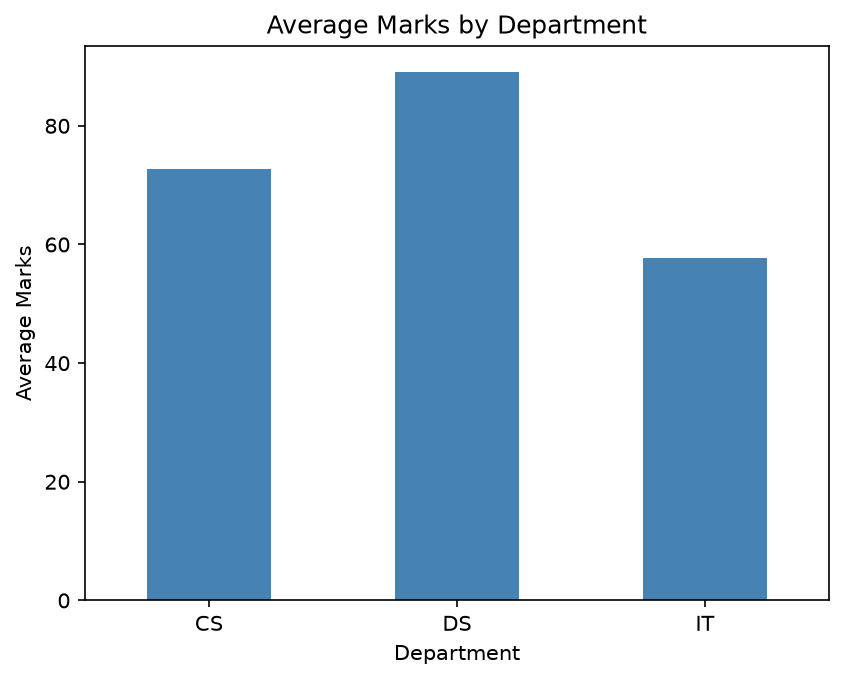

In [10]:
# Bar Chart
from IPython.display import Image, display

dept_summary["marks"].plot(kind="bar", color="steelblue")
plt.title("Average Marks by Department")
plt.xlabel("Department")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.savefig("bar_chart.png", dpi=150, bbox_inches="tight")
plt.close()

display(Image("bar_chart.png"))

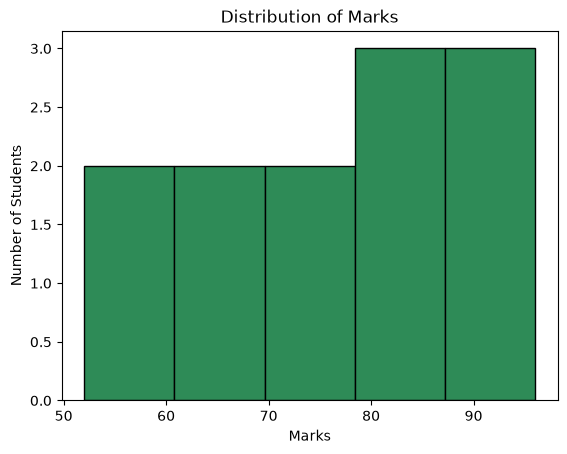

In [13]:
# Histogram
plt.hist(df["marks"], bins=5, color="seagreen", edgecolor="black")
plt.title("Distribution of Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.show()

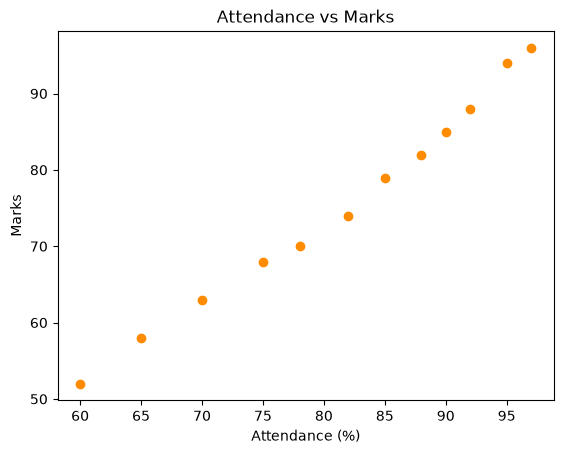

In [14]:
# Scatter plot
plt.scatter(df["attendance"], df["marks"], color="darkorange")
plt.title("Attendance vs Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Marks")
plt.show()

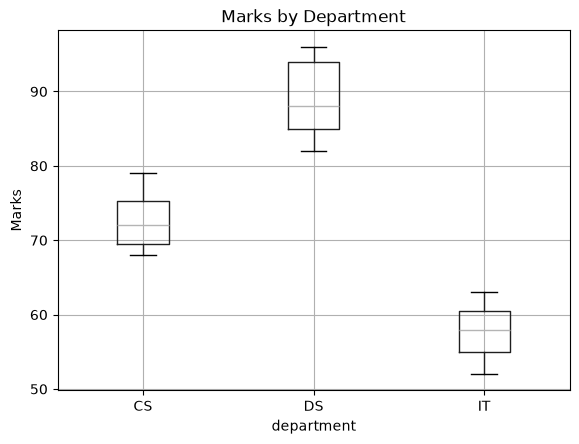

In [15]:
# Box plot
df.boxplot(column="marks", by="department")
plt.title("Marks by Department")
plt.suptitle("")
plt.ylabel("Marks")
plt.show()

Insight:
- Bar chart: DS has the tallest bar (about 89 marks) and IT the shortest (about 58), a gap of over 30 marks.
- Histogram: marks range from 52 to 96. Most students fall between 60 and 90, and only a few score below 60.
- Scatter plot: the points rise from bottom left to top right, so higher attendance goes with higher marks. The pattern is very tight, which suggests a strong positive relationship.
- Box plot: DS has the highest median, and IT's whole box sits below the others. The departments barely overlap, so the department differences are large in this small sample.

5. Basic Analysis

In [16]:
# Summary statistics
df[["attendance", "study_hours", "marks"]].describe().round(2)

,attendance,study_hours,marks
count,12.00,12.00,12.00
mean,81.42,2.71,75.75
std,11.99,1.05,14.03
min,60.00,1.00,52.00
25%,73.75,2.00,66.75
50%,83.50,2.75,76.50
75%,90.50,3.50,85.75
max,97.00,4.50,96.00


             attendance  study_hours  marks
attendance        1.000        0.971  0.994
study_hours       0.971        1.000  0.987
marks             0.994        0.987  1.000


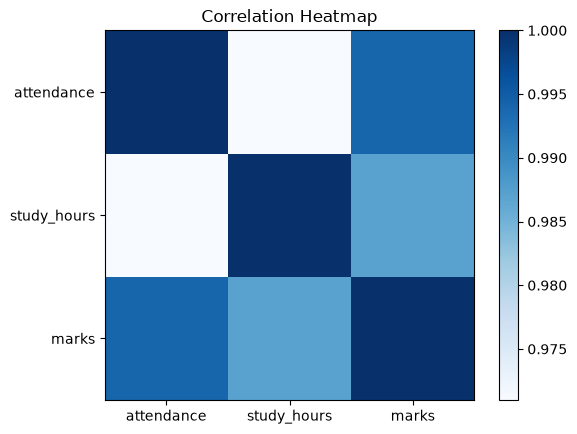

In [17]:
# Correlation
corr = df[["attendance", "study_hours", "marks"]].corr().round(3)
print(corr)

plt.imshow(corr, cmap="Blues")
plt.colorbar()
plt.xticks(range(3), corr.columns)
plt.yticks(range(3), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

Insight:
- The average mark is 75.75 and the median is 76.5, so the marks are balanced with no extreme values. The standard deviation is about 14, so marks vary quite a lot between students.
- Attendance and marks have a correlation of 0.994, and study hours and marks have 0.987. Both are very close to 1, so more attendance and more study hours go with higher marks.
- Attendance and study hours are also highly related (0.971), so it is hard to say which of the two matters more.
- This is a small sample of 12 students, and correlation does not prove causation. The dataset is also made up for practice, so these results are not real-world findings.

6. Conclusion

In this task, I:
- Set up Python, Jupyter, NumPy, Pandas and Matplotlib.
- Created a dataset and checked its structure and missing values.
- Manipulated data by filtering, sorting, adding a column and grouping.
- Made four charts: bar chart, histogram, scatter plot and box plot.
- Calculated summary statistics and correlations.

Main finding: in this dataset, higher attendance and more study hours go with higher marks, and the DS department scored highest. Next step: apply these skills to a real-world dataset in Task 3.